In [2]:
#Importing for both Phases I,II.
!pip install -q opencv-python-headless mediapipe scikit-image tensorflow

import os
import numpy as np
import cv2
import mediapipe as mp
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from skimage.feature import hog


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.7/35.7 MB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 1.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opentelemetry-proto 1.37.0 requires protobuf<7.0,>=5.0, but you have protobuf 4.25.8 which is incompatible.
ydf 0.13.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 4.25.8 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 4.25.8 which is incompatible.


In [3]:
#Drive Mount + Defining Data Paths

drive.mount('/content/drive')

dataset_root = "/content/drive/MyDrive/datasets/FER-2023 Dataset"
train_dir = os.path.join(dataset_root, "train")
test_dir  = os.path.join(dataset_root, "test")

emotion_dict = {
    0: "Angry",
    1: "Disgust",
    2: "Fear",
    3: "Happy",
    4: "Sad",
    5: "Surprise",
    6: "Neutral"
}


In [5]:
#Loading the Dataset with no processing

def load_dataset(root_dir):
    images = []
    labels = []
    class_map = {}
    class_idx = 0

    for emotion in sorted(os.listdir(root_dir)):
        path = os.path.join(root_dir, emotion)
        if not os.path.isdir(path):
            continue

        class_map[emotion] = class_idx
        label = class_idx
        class_idx += 1

        for fname in os.listdir(path):
            file_path = os.path.join(path, fname)
            try:
                img = load_img(file_path, color_mode='grayscale', target_size=(48,48))
                img = img_to_array(img).astype('float32') / 255.0
                images.append(img)
                labels.append(label)
            except:
                pass

    return np.array(images), np.array(labels), class_map


X_train_img, y_train_int, class_map = load_dataset(train_dir)
X_test_img,  y_test_int,  _         = load_dataset(test_dir)

# Create validation set (20%)
X_train_img, X_val_img, y_train_int, y_val_int = train_test_split(
    X_train_img, y_train_int, test_size=0.2, random_state=42, stratify=y_train_int
)

print("Loaded images:")
print("Train:", X_train_img.shape)
print("Val  :", X_val_img.shape)
print("Test :", X_test_img.shape)
print("Classes:", class_map)


Loaded images:
Train: (22967, 48, 48, 1)
Val  : (5742, 48, 48, 1)
Test : (7178, 48, 48, 1)
Classes: {'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}


In [6]:
#HAAR Cascade Face Detection & Cropping

face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

def detect_and_crop_face(img):
    img2d = (img.squeeze() * 255).astype('uint8')

    faces = face_cascade.detectMultiScale(img2d, 1.3, 5)

    if len(faces) == 0:
        # fallback: return image as 48×48
        return cv2.resize(img2d, (48,48))

    # Select largest face
    x, y, w, h = max(faces, key=lambda box: box[2] * box[3])
    face = img2d[y:y+h, x:x+w]

    face48 = cv2.resize(face, (48, 48))
    return face48


In [7]:
#Facial Landmark Extraction + Alignment (MediaPipe)

mp_face = mp.solutions.face_mesh
face_mesh = mp_face.FaceMesh(static_image_mode=True)

def align_face(face48):
    rgb = cv2.cvtColor(face48, cv2.COLOR_GRAY2RGB)

    results = face_mesh.process(rgb)
    if not results.multi_face_landmarks:
        return face48  # no alignment possible

    lm = results.multi_face_landmarks[0].landmark

    # eye landmark indices (MediaPipe standard)
    left_eye  = np.array([lm[33].x, lm[33].y])
    right_eye = np.array([lm[263].x, lm[263].y])

    dy = right_eye[1] - left_eye[1]
    dx = right_eye[0] - left_eye[0]
    angle = np.degrees(np.arctan2(dy, dx))

    h, w = face48.shape
    M = cv2.getRotationMatrix2D((w//2, h//2), angle, 1)
    aligned = cv2.warpAffine(face48, M, (w, h))

    return aligned


In [8]:
#Resize + Normalize (Final Preprocessing Step)

def normalize_face(face48):
    face = face48.astype('float32') / 255.0
    return face

In [9]:
#Full Preprocessing Pipeline

def preprocess_face(img):
    cropped = detect_and_crop_face(img)
    aligned = align_face(cropped)
    normalized = normalize_face(aligned)
    return normalized

In [10]:
#HOG Feature Extraction

def extract_hog_features(img):
    return hog(
        img,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm='L2-Hys'
    )

In [11]:
#Gabor Filter Bank Creation

def build_gabor_kernels():
    kernels = []
    ksize = 9
    sigmas = [1.0, 2.0]
    thetas = [0, np.pi/4, np.pi/2, 3*np.pi/4]
    lambdas = [np.pi/4, np.pi/2]
    gammas = [0.5, 1.0]

    for theta in thetas:
        for sigma in sigmas:
            for lambd in lambdas:
                for gamma in gammas:
                    kern = cv2.getGaborKernel(
                        (ksize, ksize),
                        sigma,
                        theta,
                        lambd,
                        gamma,
                        0,
                        ktype=cv2.CV_32F
                    )
                    kernels.append(kern)

    return kernels


gabor_kernels = build_gabor_kernels()
print("Gabor filters created:", len(gabor_kernels))

Gabor filters created: 32


In [12]:
#Gabor Feature Extraction

def extract_gabor_features(img):
    img2d = img.squeeze()
    features = []

    for kern in gabor_kernels:
        filtered = cv2.filter2D(img2d, cv2.CV_32F, kern)
        features.append(filtered.mean())
        features.append(filtered.var())

    return np.array(features)

In [13]:
#Landmark Feature Extraction (Geometry)

def extract_landmark_features(img):
    rgb = cv2.cvtColor((img * 255).astype('uint8'), cv2.COLOR_GRAY2RGB)
    results = face_mesh.process(rgb)

    if not results.multi_face_landmarks:
        return np.zeros(468*2)  # no landmarks found

    lm = results.multi_face_landmarks[0].landmark
    coords = []
    for p in lm:
        coords.extend([p.x, p.y])

    return np.array(coords)


In [14]:
#Extract ALL Features (Fusion), combined feature extraction

def extract_all_features(images):
    all_features = []

    for img in tqdm(images):
        pre = preprocess_face(img)
        hog_f   = extract_hog_features(pre)
        gabor_f = extract_gabor_features(pre)
        lm_f    = extract_landmark_features(pre)

        combined = np.concatenate([hog_f, gabor_f, lm_f])
        all_features.append(combined)

    return np.array(all_features)


X_train_feat = extract_all_features(X_train_img)
X_val_feat   = extract_all_features(X_val_img)
X_test_feat  = extract_all_features(X_test_img)

print("Feature vector size:", X_train_feat.shape[1])


  0%|          | 0/22967 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '
100%|██████████| 7178/7178 [03:30<00:00, 34.07it/s]


Feature vector size: 1900


In [15]:
#SVM Training Classifier
model_svm = LinearSVC(C=1.0, max_iter=8000)
model_svm.fit(X_train_feat, y_train_int)

print("Training finished.")

Training finished.


Accuracy: 0.5222903315686821
              precision    recall  f1-score   support

       angry       0.40      0.37      0.38       958
     disgust       0.46      0.20      0.28       111
        fear       0.37      0.19      0.25      1024
       happy       0.69      0.84      0.76      1774
     neutral       0.46      0.54      0.50      1233
         sad       0.39      0.41      0.40      1247
    surprise       0.62      0.63      0.62       831

    accuracy                           0.52      7178
   macro avg       0.48      0.45      0.46      7178
weighted avg       0.50      0.52      0.51      7178



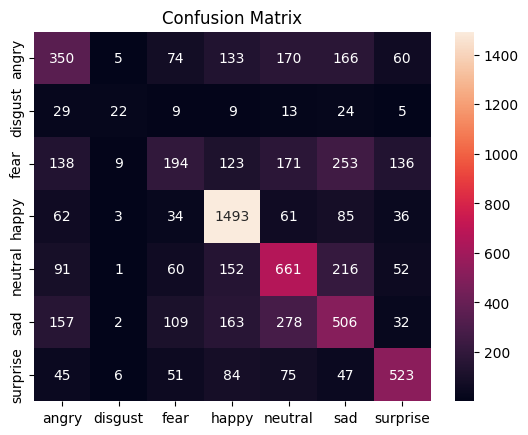

In [16]:
#Model Evaluation

y_pred = model_svm.predict(X_test_feat)

print("Accuracy:", accuracy_score(y_test_int, y_pred))
print(classification_report(y_test_int, y_pred, target_names=list(class_map.keys())))

cm = confusion_matrix(y_test_int, y_pred)
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=list(class_map.keys()),
            yticklabels=list(class_map.keys()))
plt.title("Confusion Matrix")
plt.show()


In [28]:
#Upload your photo from here!

from google.colab import files

def predict_image_phase1():
    uploaded = files.upload()
    for fname in uploaded.keys():
        img = load_img(fname, color_mode='grayscale', target_size=(48,48))
        img = img_to_array(img).astype('float32')/255.0

        pre = preprocess_face(img)
        hog_f   = extract_hog_features(pre)
        gabor_f = extract_gabor_features(pre)
        lm_f    = extract_landmark_features(pre)

        feat = np.concatenate([hog_f, gabor_f, lm_f]).reshape(1,-1)

        pred = model_svm.predict(feat)[0]
        emotion = list(class_map.keys())[pred]
        print("Predicted Emotion:", emotion)

predict_image_phase1()
